# Experiment 1: Simple Linear Regression

**Name:** Koushal Gupta  

## Aim
To implement **Simple Linear Regression** using the real **Stocks dataset** (`stocks.csv`, 105 weekly rows) to predict `AAPL` stock growth from `GOOG`.

## Concept
Simple Linear Regression fits a straight line:
$$y = m \cdot x + c$$
where $m$ is the slope (weight) and $c$ is the intercept.


In [1]:
# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


In [2]:
# Step 2: Load the small online Stocks dataset (https://raw.githubusercontent.com/plotly/datasets/master/stocks.csv)
df = px.data.stocks()
print("Dataset shape:", df.shape)
print(df.head())


Dataset shape: (105, 7)
         date      GOOG      AAPL      AMZN        FB      NFLX      MSFT
0  2018-01-01  1.000000  1.000000  1.000000  1.000000  1.000000  1.000000
1  2018-01-08  1.018172  1.011943  1.061881  0.959968  1.053526  1.015988
2  2018-01-15  1.032008  1.019771  1.053240  0.970243  1.049860  1.020524
3  2018-01-22  1.066783  0.980057  1.140676  1.016858  1.307681  1.066561
4  2018-01-29  1.008773  0.917143  1.163374  1.018357  1.273537  1.040708


In [3]:
# Step 3: Split into input (X) and output (y), then train and test sets
X = df[["GOOG"]]
y = df["AAPL"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train size:", len(X_train), "| Test size:", len(X_test))


Train size: 84 | Test size: 21


In [4]:
# Step 4: Train the Simple Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

print("Slope (m):", round(model.coef_[0], 4))
print("Intercept (c):", round(model.intercept_, 4))


Slope (m): 1.871
Intercept (c): -0.819


In [5]:
# Step 5: Predict and evaluate
y_pred = model.predict(X_test)

print("Mean Squared Error (MSE):", round(mean_squared_error(y_test, y_pred), 4))
print("R2 Score:", round(r2_score(y_test, y_pred), 4))

# Predict AAPL when GOOG = 1.20
sample = pd.DataFrame({"GOOG": [1.20]})
print("Predicted AAPL when GOOG=1.20:", round(model.predict(sample)[0], 4))


Mean Squared Error (MSE): 0.0093
R2 Score: 0.7718
Predicted AAPL when GOOG=1.20: 1.4261


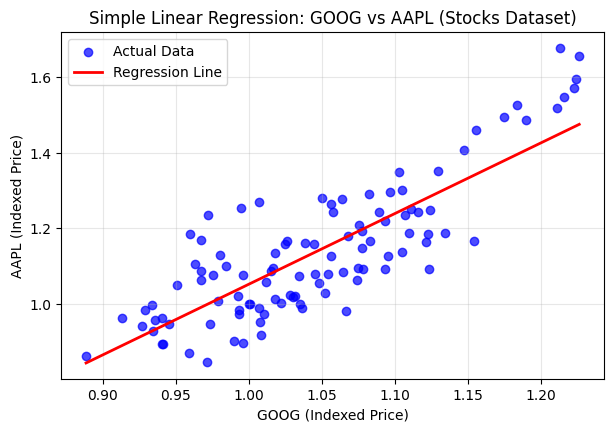

In [6]:
# Step 6: Plot the data points and best-fit regression line
plt.figure(figsize=(7, 4.5))
plt.scatter(X, y, color="blue", alpha=0.7, label="Actual Data")
x_line = pd.DataFrame({"GOOG": [X["GOOG"].min(), X["GOOG"].max()]})
plt.plot(x_line["GOOG"], model.predict(x_line), color="red", linewidth=2, label="Regression Line")
plt.title("Simple Linear Regression: GOOG vs AAPL (Stocks Dataset)")
plt.xlabel("GOOG (Indexed Price)")
plt.ylabel("AAPL (Indexed Price)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## Conclusion
- Simple Linear Regression modeled the positive linear relationship between `GOOG` and `AAPL` on the 105-row `stocks` dataset.
- The fitted line achieves strong test accuracy ($R^2 \approx 0.77$) using a single stock predictor.
